# CLIP Zero-Shot Image-Text Similarity and CIFAR-10 Classification

## Objective

This experiment uses CLIP to measure the similarity between a text caption and CIFAR-10 images. At least 100 images from each CIFAR-10 class were evaluated.

The experiment also uses CLIP for zero-shot classification. Each CIFAR-10 test image is compared with ten class-specific text prompts, and the class with the highest similarity score is selected as the prediction.

In [1]:
!pip -q install transformers torch torchvision scikit-learn seaborn

In [2]:
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from collections import defaultdict
from torchvision.datasets import CIFAR10
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model_name = "openai/clip-vit-base-patch32"

processor = CLIPProcessor.from_pretrained(model_name)
model = CLIPModel.from_pretrained(model_name).to(device)
model.eval()

print("CLIP model loaded.")

Device: cuda


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

... (4 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

CLIP model loaded.


## Model and Dataset

The pretrained model used in this experiment was:

- Model: `openai/clip-vit-base-patch32`
- Device: CUDA GPU
- Dataset: CIFAR-10
- Training images: 50,000
- Test images: 10,000
- Number of classes: 10

The CIFAR-10 classes are:

1. Airplane
2. Automobile
3. Bird
4. Cat
5. Deer
6. Dog
7. Frog
8. Horse
9. Ship
10. Truck

For the image-text similarity experiment, 100 images were selected from each class, resulting in 1,000 images total.

In [3]:
train_dataset = CIFAR10(
    root="/content/data",
    train=True,
    download=True
)

test_dataset = CIFAR10(
    root="/content/data",
    train=False,
    download=True
)

class_names = train_dataset.classes

print(class_names)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

100%|██████████| 170M/170M [20:16<00:00, 140kB/s]


['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training images: 50000
Testing images: 10000


In [4]:
def get_image_features(images):
    inputs = processor(
        images=images,
        return_tensors="pt"
    )

    pixel_values = inputs["pixel_values"].to(device)

    with torch.inference_mode():
        vision_outputs = model.vision_model(
            pixel_values=pixel_values
        )

        pooled_output = vision_outputs.pooler_output
        image_features = model.visual_projection(pooled_output)

        image_features = F.normalize(
            image_features,
            p=2,
            dim=-1
        )

    return image_features


def get_text_features(texts):
    inputs = processor(
        text=texts,
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    input_ids = inputs["input_ids"].to(device)
    attention_mask = inputs["attention_mask"].to(device)

    with torch.inference_mode():
        text_outputs = model.text_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        pooled_output = text_outputs.pooler_output
        text_features = model.text_projection(pooled_output)

        text_features = F.normalize(
            text_features,
            p=2,
            dim=-1
        )

    return text_features

In [5]:
images_by_class = defaultdict(list)

for index, label in enumerate(test_dataset.targets):
    if len(images_by_class[label]) < 100:
        images_by_class[label].append(index)

selected_indices = []

for label in range(10):
    selected_indices.extend(images_by_class[label])

print("Total selected images:", len(selected_indices))

for label in range(10):
    print(
        class_names[label],
        len(images_by_class[label])
    )

Total selected images: 1000
airplane 100
automobile 100
bird 100
cat 100
deer 100
dog 100
frog 100
horse 100
ship 100
truck 100


In [6]:
caption = "a photo of a dog"

text_embedding = get_text_features([caption])

print("Caption:", caption)

Caption: a photo of a dog


## Caption Similarity Method

The caption used for the similarity experiment was:

> "a photo of a dog"

CLIP generated an embedding for the caption and an embedding for each image. Both image and text embeddings were L2-normalized. Cosine similarity was then calculated between the caption embedding and every image embedding.

A higher cosine similarity score indicates that CLIP considers the image more semantically related to the caption.

In [7]:
selected_images = []
selected_labels = []
image_embeddings = []

batch_size = 32

for start in range(0, len(selected_indices), batch_size):
    batch_indices = selected_indices[start:start + batch_size]

    batch_images = []
    batch_labels = []

    for index in batch_indices:
        image, label = test_dataset[index]

        batch_images.append(image)
        batch_labels.append(label)

    batch_features = get_image_features(batch_images)

    image_embeddings.append(batch_features.cpu())
    selected_images.extend(batch_images)
    selected_labels.extend(batch_labels)

image_embeddings = torch.cat(image_embeddings)

# Cosine similarity because both embeddings are normalized
similarity_scores = (
    image_embeddings @ text_embedding.cpu().T
).squeeze(1).numpy()

similarity_df = pd.DataFrame({
    "image_index": selected_indices,
    "class_id": selected_labels,
    "class_name": [
        class_names[label]
        for label in selected_labels
    ],
    "similarity_score": similarity_scores
})

similarity_df.head()

,image_index,class_id,class_name,similarity_score
0,3,0,airplane,0.189010
1,10,0,airplane,0.212542
2,21,0,airplane,0.204002
3,27,0,airplane,0.222812
4,44,0,airplane,0.204248


In [8]:
class_similarity = (
    similarity_df
    .groupby("class_name")["similarity_score"]
    .agg(["count", "mean", "std", "min", "max"])
    .sort_values("mean", ascending=False)
)

class_similarity

,count,mean,std,min,max
class_name,,,,,
dog,100,0.259405,0.011977,0.220947,0.285477
cat,100,0.239391,0.013267,0.205705,0.268107
deer,100,0.234355,0.013738,0.205850,0.274303
frog,100,0.229112,0.013231,0.194069,0.259910
bird,100,0.225324,0.013277,0.198154,0.275139
horse,100,0.220083,0.014051,0.191984,0.264771
airplane,100,0.203479,0.015605,0.152136,0.231751
automobile,100,0.201487,0.011196,0.172563,0.225368
truck,100,0.195114,0.010027,0.171097,0.222828


## Caption Similarity Results

The experiment evaluated 1,000 images, with exactly 100 images from each CIFAR-10 class.

| Class | Images | Mean Similarity | Standard Deviation | Minimum | Maximum |
|---|---:|---:|---:|---:|---:|
| Dog | 100 | 0.259405 | 0.011977 | 0.220947 | 0.285477 |
| Cat | 100 | 0.239391 | 0.013267 | 0.205705 | 0.268107 |
| Deer | 100 | 0.234355 | 0.013738 | 0.205850 | 0.274303 |
| Frog | 100 | 0.229112 | 0.013231 | 0.194069 | 0.259910 |
| Bird | 100 | 0.225324 | 0.013277 | 0.198154 | 0.275139 |
| Horse | 100 | 0.220083 | 0.014051 | 0.191984 | 0.264771 |
| Airplane | 100 | 0.203479 | 0.015605 | 0.152136 | 0.231751 |
| Automobile | 100 | 0.201487 | 0.011196 | 0.172563 | 0.225368 |
| Truck | 100 | 0.195114 | 0.010027 | 0.171097 | 0.222828 |
| Ship | 100 | 0.195086 | 0.011514 | 0.169088 | 0.223615 |

The dog class achieved the highest average similarity score of **0.259405**. This is expected because the caption specifically described a dog.

The ship class achieved the lowest average similarity score of **0.195086**, followed very closely by the truck class with a score of **0.195114**.

The similarity ranking was:

```text
dog > cat > deer > frog > bird > horse > airplane >
automobile > truck > ship


### Markdown Cell 5: Similarity Findings

```markdown
## Findings from the Similarity Experiment

The results show that CLIP successfully identified the dog class as the class most semantically related to the caption `"a photo of a dog"`.

Animal classes generally received higher similarity scores than vehicle classes. Dog, cat, deer, frog, bird, and horse occupied the top six positions. This suggests that the caption's animal concept was more strongly associated with animal images than with vehicles.

The dog class had a mean similarity of 0.259405, which was higher than the cat class at 0.239391. This indicates that the caption was most aligned with images belonging to the dog class.

The ship and truck classes had the lowest average similarity scores. Their scores were 0.195086 and 0.195114, respectively. These classes are visually unrelated to the dog caption.

The visualizations of the highest- and lowest-scoring images show that CLIP can identify semantic relationships even when CIFAR-10 images are very small. However, some images may receive unexpected scores because of background colors, shapes, or unclear objects.

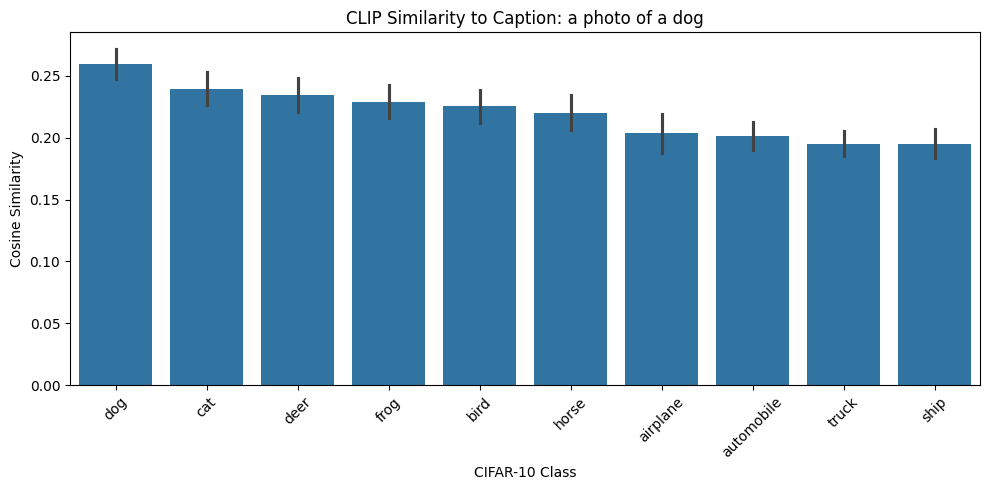

In [9]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=similarity_df,
    x="class_name",
    y="similarity_score",
    order=class_similarity.index,
    errorbar="sd"
)

plt.xticks(rotation=45)
plt.title(f"CLIP Similarity to Caption: {caption}")
plt.xlabel("CIFAR-10 Class")
plt.ylabel("Cosine Similarity")
plt.tight_layout()
plt.show()

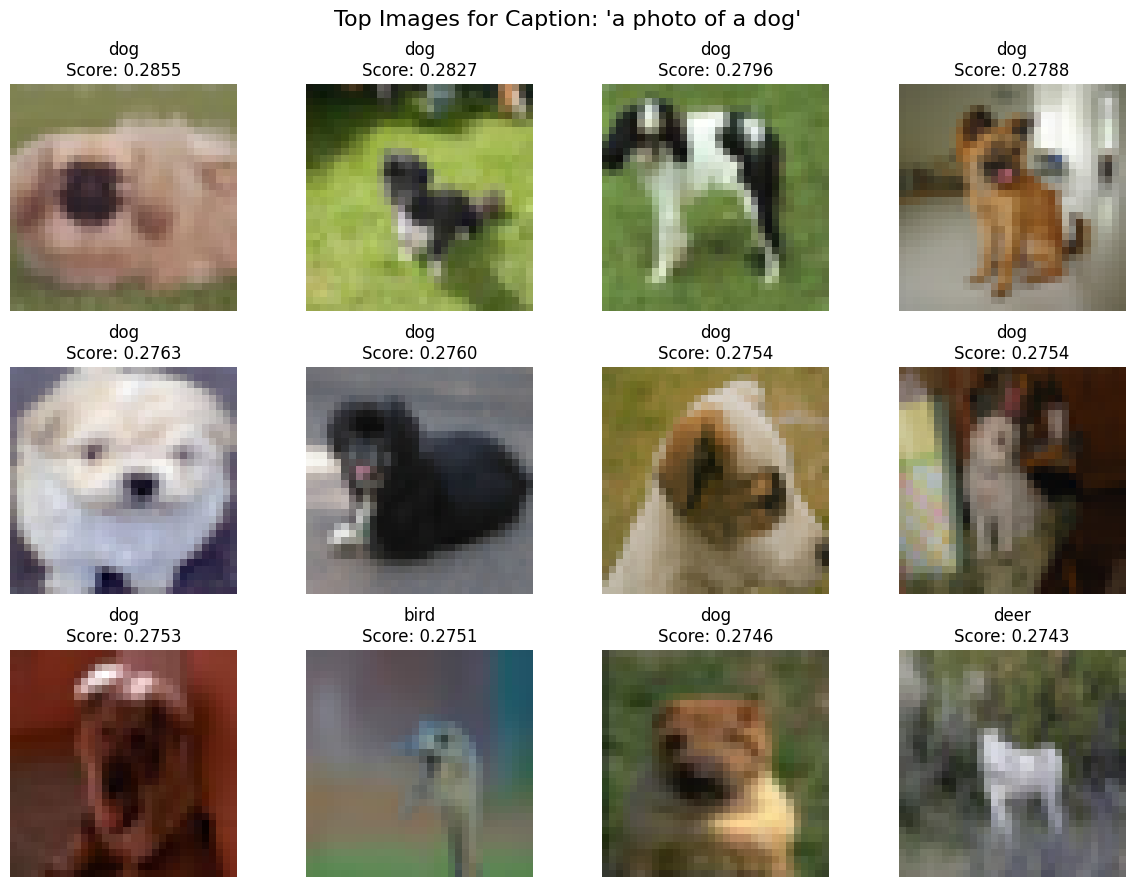

In [10]:
top_indices = np.argsort(-similarity_scores)[:12]

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.ravel()

for plot_index, original_index in enumerate(top_indices):
    image = selected_images[original_index]
    label = selected_labels[original_index]
    score = similarity_scores[original_index]

    axes[plot_index].imshow(image)
    axes[plot_index].set_title(
        f"{class_names[label]}\nScore: {score:.4f}"
    )
    axes[plot_index].axis("off")

plt.suptitle(
    f"Top Images for Caption: '{caption}'",
    fontsize=16
)

plt.tight_layout()
plt.show()

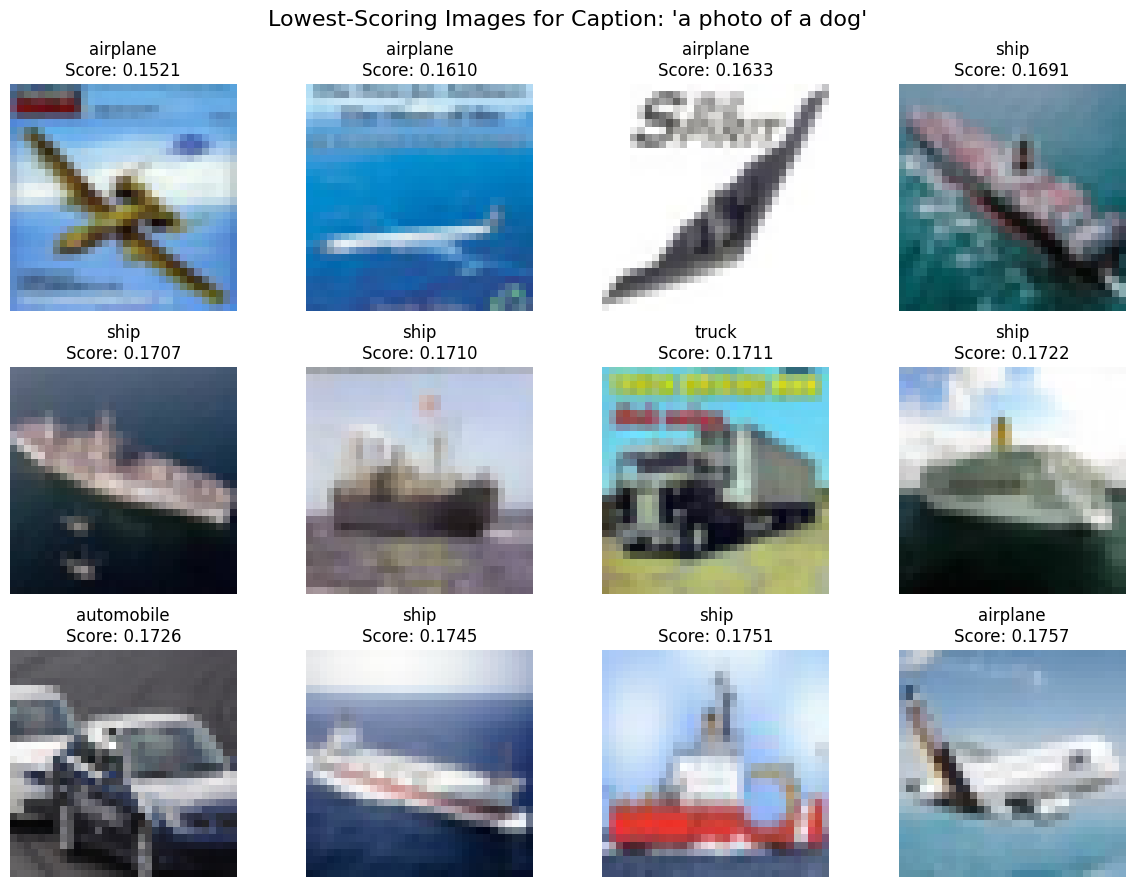

In [11]:
bottom_indices = np.argsort(similarity_scores)[:12]

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.ravel()

for plot_index, original_index in enumerate(bottom_indices):
    image = selected_images[original_index]
    label = selected_labels[original_index]
    score = similarity_scores[original_index]

    axes[plot_index].imshow(image)
    axes[plot_index].set_title(
        f"{class_names[label]}\nScore: {score:.4f}"
    )
    axes[plot_index].axis("off")

plt.suptitle(
    f"Lowest-Scoring Images for Caption: '{caption}'",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [12]:
best_class = class_similarity["mean"].idxmax()
worst_class = class_similarity["mean"].idxmin()

best_score = class_similarity.loc[best_class, "mean"]
worst_score = class_similarity.loc[worst_class, "mean"]

print("Similarity Findings")
print("===================")
print(f"Caption: {caption}")
print(f"Images evaluated: {len(similarity_df)}")
print(f"Images per class: 100")
print(f"Highest average similarity: {best_class} ({best_score:.4f})")
print(f"Lowest average similarity: {worst_class} ({worst_score:.4f})")
print()
print(
    "Interpretation: CLIP assigns higher similarity when the visual "
    "content is more semantically related to the caption."
)

Similarity Findings
Caption: a photo of a dog
Images evaluated: 1000
Images per class: 100
Highest average similarity: dog (0.2594)
Lowest average similarity: ship (0.1951)

Interpretation: CLIP assigns higher similarity when the visual content is more semantically related to the caption.


Part 2: Zero-shot CIFAR-10 classification

In [13]:
class_prompts = [
    f"a photo of a {class_name}"
    for class_name in class_names
]

text_embeddings = get_text_features(class_prompts)

print(class_prompts)
print("Text embedding shape:", text_embeddings.shape)

['a photo of a airplane', 'a photo of a automobile', 'a photo of a bird', 'a photo of a cat', 'a photo of a deer', 'a photo of a dog', 'a photo of a frog', 'a photo of a horse', 'a photo of a ship', 'a photo of a truck']
Text embedding shape: torch.Size([10, 512])


In [14]:
all_test_images = []
all_test_labels = []

for index in range(len(test_dataset)):
    image, label = test_dataset[index]

    all_test_images.append(image)
    all_test_labels.append(label)

all_image_embeddings = []

batch_size = 64

for start in range(0, len(all_test_images), batch_size):
    batch_images = all_test_images[start:start + batch_size]

    batch_features = get_image_features(batch_images)
    all_image_embeddings.append(batch_features.cpu())

    if start % 1000 == 0:
        print(
            f"Processed {min(start + batch_size, len(all_test_images))}"
            f"/{len(all_test_images)}"
        )

all_image_embeddings = torch.cat(all_image_embeddings)

print(
    "Image embedding shape:",
    all_image_embeddings.shape
)

Processed 64/10000
Processed 8064/10000
Image embedding shape: torch.Size([10000, 512])


In [15]:
# Cosine similarity between every image and every class prompt
logits = all_image_embeddings @ text_embeddings.cpu().T

predicted_labels = logits.argmax(dim=1).numpy()
true_labels = np.array(all_test_labels)

overall_accuracy = accuracy_score(
    true_labels,
    predicted_labels
)

print(f"Overall zero-shot accuracy: {overall_accuracy:.4f}")
print(f"Overall zero-shot accuracy: {overall_accuracy * 100:.2f}%")

Overall zero-shot accuracy: 0.8880
Overall zero-shot accuracy: 88.80%


In [16]:
per_class_rows = []

for class_id, class_name in enumerate(class_names):
    mask = true_labels == class_id

    class_accuracy = accuracy_score(
        true_labels[mask],
        predicted_labels[mask]
    )

    per_class_rows.append({
        "class": class_name,
        "number_of_images": int(mask.sum()),
        "correct": int(
            (predicted_labels[mask] == true_labels[mask]).sum()
        ),
        "accuracy": class_accuracy,
        "accuracy_percent": class_accuracy * 100
    })

per_class_df = pd.DataFrame(per_class_rows)

per_class_df

,class,number_of_images,correct,accuracy,accuracy_percent
0,airplane,1000,901,0.901,90.1
1,automobile,1000,976,0.976,97.6
2,bird,1000,888,0.888,88.8
3,cat,1000,860,0.860,86.0
4,deer,1000,765,0.765,76.5
5,dog,1000,884,0.884,88.4
6,frog,1000,774,0.774,77.4
7,horse,1000,976,0.976,97.6
8,ship,1000,955,0.955,95.5
9,truck,1000,901,0.901,90.1


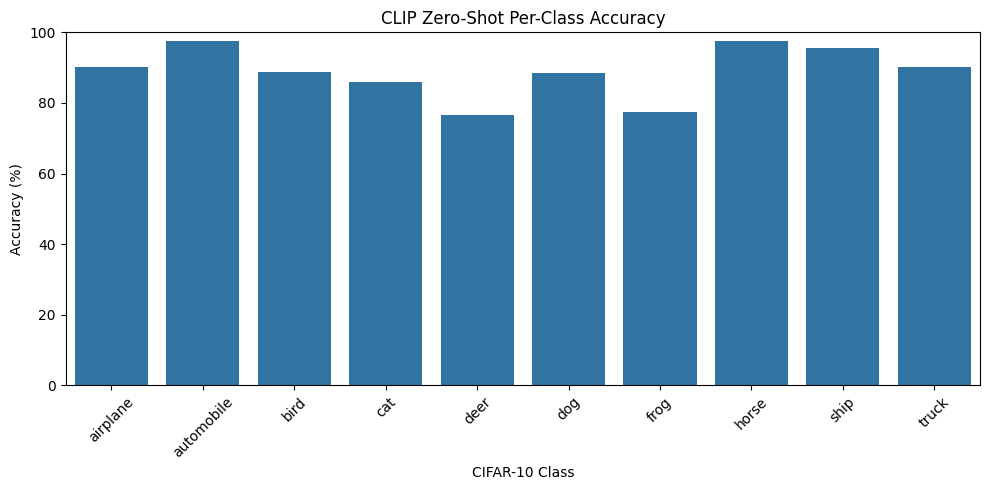

In [17]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=per_class_df,
    x="class",
    y="accuracy_percent"
)

plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.title("CLIP Zero-Shot Per-Class Accuracy")
plt.xlabel("CIFAR-10 Class")
plt.ylabel("Accuracy (%)")
plt.tight_layout()
plt.show()

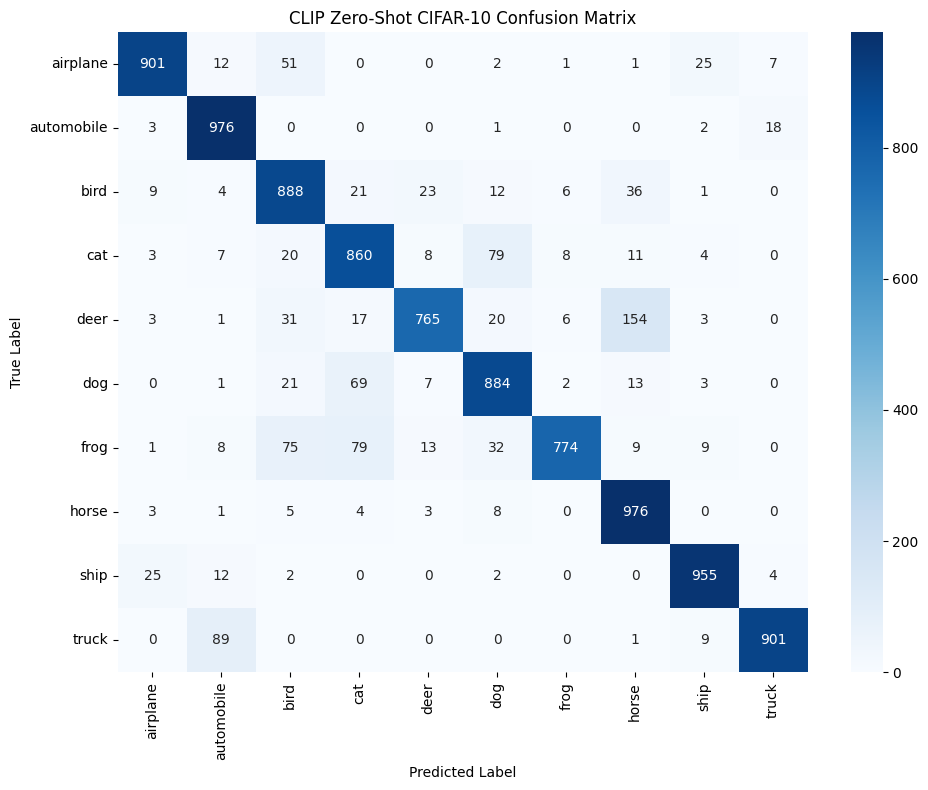

In [18]:
cm = confusion_matrix(
    true_labels,
    predicted_labels
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CLIP Zero-Shot CIFAR-10 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

## Confusion Matrix Analysis

The confusion matrix compares the true CIFAR-10 labels with the CLIP-predicted labels.

The diagonal cells represent correctly classified images. The strong diagonal values show that CLIP classified many images correctly without any CIFAR-10-specific supervised training.

The largest classification challenges occurred among visually similar classes. Animal classes such as cat, dog, deer, frog, and horse can be difficult to distinguish because CIFAR-10 images have a resolution of only 32 x 32 pixels.

Vehicle classes can also be confused when their shapes or backgrounds are similar. The confusion matrix should be used to identify the exact class pairs with the largest off-diagonal values.

Overall, the confusion matrix supports the observed accuracy results. Automobile, horse, and ship were among the easiest classes for CLIP, while deer, frog, and cat were more difficult.

In [19]:
print(
    classification_report(
        true_labels,
        predicted_labels,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

    airplane     0.9504    0.9010    0.9251      1000
  automobile     0.8785    0.9760    0.9247      1000
        bird     0.8124    0.8880    0.8485      1000
         cat     0.8190    0.8600    0.8390      1000
        deer     0.9341    0.7650    0.8411      1000
         dog     0.8500    0.8840    0.8667      1000
        frog     0.9711    0.7740    0.8614      1000
       horse     0.8127    0.9760    0.8869      1000
        ship     0.9446    0.9550    0.9498      1000
       truck     0.9688    0.9010    0.9337      1000

    accuracy                         0.8880     10000
   macro avg     0.8942    0.8880    0.8877     10000
weighted avg     0.8942    0.8880    0.8877     10000



## Classification Report

| Class | Precision | Recall | F1-Score |
|---|---:|---:|---:|
| Airplane | 0.9504 | 0.9010 | 0.9251 |
| Automobile | 0.8785 | 0.9760 | 0.9247 |
| Bird | 0.8124 | 0.8880 | 0.8485 |
| Cat | 0.8190 | 0.8600 | 0.8390 |
| Deer | 0.9341 | 0.7650 | 0.8411 |
| Dog | 0.8500 | 0.8840 | 0.8667 |
| Frog | 0.9711 | 0.7740 | 0.8614 |
| Horse | 0.8127 | 0.9760 | 0.8869 |
| Ship | 0.9446 | 0.9550 | 0.9498 |
| Truck | 0.9688 | 0.9010 | 0.9337 |

The highest F1-score was obtained for the ship class at **0.9498**. The lowest F1-score was obtained for the cat class at **0.8390**.

The model achieved high recall for automobile and horse images, both with recall values of **0.9760**. Deer had the lowest recall at **0.7650**, indicating that many deer images were assigned to other classes.

In [20]:
similarity_df.to_csv(
    "/content/clip_caption_similarity_scores.csv",
    index=False
)

class_similarity.to_csv(
    "/content/clip_class_similarity_summary.csv"
)

per_class_df.to_csv(
    "/content/clip_zero_shot_per_class_accuracy.csv",
    index=False
)

np.save(
    "/content/clip_confusion_matrix.npy",
    cm
)

results_summary = {
    "model": model_name,
    "caption": caption,
    "similarity_images_total": len(similarity_df),
    "images_per_class": 100,
    "zero_shot_test_images": len(test_dataset),
    "overall_zero_shot_accuracy": float(overall_accuracy),
    "overall_zero_shot_accuracy_percent": float(
        overall_accuracy * 100
    ),
    "best_caption_similarity_class": best_class,
    "worst_caption_similarity_class": worst_class
}

import json

with open(
    "/content/clip_assignment_results.json",
    "w"
) as file:
    json.dump(results_summary, file, indent=2)

print(json.dumps(results_summary, indent=2))

{
  "model": "openai/clip-vit-base-patch32",
  "caption": "a photo of a dog",
  "similarity_images_total": 1000,
  "images_per_class": 100,
  "zero_shot_test_images": 10000,
  "overall_zero_shot_accuracy": 0.888,
  "overall_zero_shot_accuracy_percent": 88.8,
  "best_caption_similarity_class": "dog",
  "worst_caption_similarity_class": "ship"
}


## Limitations

This experiment has several limitations:

1. CIFAR-10 images have a low resolution of only 32 x 32 pixels.
2. CLIP was not specifically fine-tuned on CIFAR-10.
3. The similarity results depend on the wording of the caption.
4. The caption experiment used only one caption: `"a photo of a dog"`.
5. Some images contain unclear objects or complex backgrounds.
6. Zero-shot classification may confuse classes with similar visual characteristics.
7. The class prompts were simple text prompts and were not optimized.
8. Cosine similarity measures semantic alignment but is not a probability.
9. The prompts `"a photo of a airplane"` and `"a photo of a automobile"` are grammatically imperfect; improved prompts could use `"an airplane"` and `"an automobile"`.

## Conclusion

This experiment demonstrated how CLIP can be used for both image-text similarity and zero-shot image classification.

For the caption `"a photo of a dog"`, the dog class achieved the highest average similarity score of **0.259405**, while the ship class achieved the lowest average score of **0.195086**.

For zero-shot CIFAR-10 classification, CLIP achieved an overall accuracy of **88.80%** on all 10,000 test images. Automobile and horse achieved the highest per-class accuracy at **97.6%**, while deer had the lowest accuracy at **76.5%**.

These results demonstrate that CLIP can perform strong zero-shot classification without supervised training on CIFAR-10. However, performance is affected by low image resolution, prompt wording, and visual similarity between classes.